# 07 · Estabilidad de los clusters: Jackknife Clustering (Reto Avanzado 3)

En el reto 3 elegimos **k = 7** y en el reto 4 convertimos esos siete clusters en segmentos con nombre y plan de marketing. Pero antes de que marketing gaste dinero en ellos hay una pregunta que ninguna métrica anterior responde:

> **Si los datos hubieran sido un poco distintos, ¿habríamos obtenido los mismos segmentos?**

El silhouette nos dice si los grupos están bien separados *en estos datos*. No nos dice si son **reproducibles**. Un modelo puede tener un silhouette aceptable y, sin embargo, cambiar de forma drástica si quitamos unos cuantos clientes. Si eso pasa, los segmentos no describen la cartera: describen el azar de la muestra.

El **Jackknife Clustering** lo comprueba así: quitamos un trozo aleatorio de clientes, reentrenamos y miramos si cada cliente sigue en el mismo segmento. Lo repetimos muchas veces.

| Lo que pide el reto | Dónde está |
|---|---|
| Generar N submuestras excluyendo un 10-20 % y reentrenar K-Means con el mismo k | §2-§4 |
| Medir la estabilidad de las asignaciones (% de coincidencia) | §5 y §8 |
| Análisis por cluster: ¿hay algún segmento inestable? | §10 |
| ¿Hay clientes que "saltan" entre clusters? | §9, §11 y §12 |
| Gráficos que muestren las conclusiones | en cada sección (y en `outputs/figuras/07_*.png`) |
| Análisis de los clusters más y menos estables y por qué | §10-§12 |
| Recomendación final | §14 |

In [1]:
import sys
import time
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from src import config, clean, clustering, segmentos
from src import pipeline as pl

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
FIG = config.FIG_DIR  # todas las figuras se guardan en outputs/figuras
FIG.mkdir(parents=True, exist_ok=True)

## 1. Datos y modelo de referencia

Construimos la tabla de clientes directamente desde el CSV con `clean.build_client_table`, en vez de leer `clients.pkl`. Tarda unos segundos y nos garantiza que usamos exactamente la versión actual de `src/clean.py`: si alguien hubiera guardado un `clients.pkl` antiguo, el Jackknife estaría midiendo la estabilidad de otra tabla.

El **modelo de referencia** es el modelo final del reto 3: el pipeline completo (`pl.build_pipeline`, preprocesado + K-Means con k = 7) entrenado con **todos** los clientes. Numeramos los clusters por tamaño con `clustering.relabel_by_size`, igual que en los retos 3 y 4, así que el cluster 0 es "Coche en garantía", el 4 "Desconectados", etc. Los nombres los cogemos de `src/segmentos.py`.

`n_init` es el número de veces que K-Means arranca desde centros distintos (se queda con el mejor). El pipeline del equipo usa 10. Lo dejamos como parámetro porque, como veremos, es importante.

In [2]:
clientes = clean.build_client_table(clean.load_raw())
K = config.K_FINAL
NOMBRES = {i: s["nombre"] for i, s in segmentos.SEGMENTOS.items()}

def modelo(k=K, n_init=10):
    """El pipeline del equipo (preprocesado + K-Means). n_init=10 es el valor de src/pipeline.py."""
    return pl.build_pipeline(k).set_params(kmeans__n_init=n_init)

def entrenar_referencia(k=K, n_init=10):
    """Modelo con TODOS los clientes y sus etiquetas numeradas por tamaño (0 = el más grande)."""
    m = modelo(k, n_init).fit(clientes)
    return m, clustering.relabel_by_size(m.named_steps["kmeans"].labels_)

modelo_ref, ref = entrenar_referencia()

tamanos = pd.Series(ref).value_counts().sort_index().to_frame("clientes")
tamanos.insert(0, "segmento", tamanos.index.map(NOMBRES))
tamanos["%"] = (tamanos.clientes / len(ref) * 100).round(1)
tamanos.index.name = "cluster"
print(f"{len(clientes):,} clientes, k = {K}")
tamanos

173,456 clientes, k = 7


,segmento,clientes,%
cluster,,,
0,Coche en garantía,41811,24.1
1,Recién llegados,31769,18.3
2,Coche veterano,31611,18.2
3,Electrificados,27575,15.9
4,Desconectados,15660,9.0
5,Multivehículo,15327,8.8
6,Zonas premium,9703,5.6


Son los siete segmentos del reto 4, con los mismos tamaños. Esta es la "verdad" contra la que vamos a comparar cada submuestra.

## 2. Diseño del experimento

| Parámetro | Valor | Por qué |
|---|---|---|
| Número de submuestras | **20** | Es lo que sugiere el enunciado. Con 20, cada cliente queda dentro de unas 17 submuestras (entre 8 y 20), suficientes para medir su estabilidad |
| Clientes que quitamos en cada una | **15 %** (26.018) | En medio del 10-20 % que propone el enunciado: lo bastante para perturbar el modelo, sin dejarlo sin datos |
| Qué reentrenamos | **El pipeline entero** | No solo K-Means: también las medianas para imputar, los percentiles del recorte y las medias y desviaciones del escalado. Si solo reentrenáramos K-Means sobre una `X` ya escalada con todos los clientes, el 15 % "quitado" seguiría influyendo a través del escalado y la prueba sería tramposa |
| Semilla de K-Means | **La misma (42) en todas** | Así lo único que cambia entre submuestras son los datos. La estabilidad frente a la semilla ya la miramos en el reto 3 |
| Semilla de cada submuestra | 1000 + nº de submuestra | Distinta en cada una (por eso cada una quita clientes distintos) y reproducible |
| A quién asignamos | **A todos los clientes** | El modelo de cada submuestra predice el segmento de los 173.456. Así medimos dos cosas: si los clientes que **sí** estaban se quedan en su segmento, y si los que **no** estaban caen donde los puso el modelo de referencia |

La función que genera cada submuestra devuelve una **máscara**: un vector de verdadero/falso que dice qué clientes entran.

In [3]:
N_SUBMUESTRAS = 20
FRAC_FUERA = 0.15

def submuestra(r, n=len(clientes)):
    """Máscara de la submuestra r: True = el cliente entra, False = lo quitamos."""
    rng = np.random.default_rng(1000 + r)
    dentro = np.ones(n, dtype=bool)
    dentro[rng.choice(n, int(round(FRAC_FUERA * n)), replace=False)] = False
    return dentro

m0 = submuestra(0)
print(f"Submuestra 1: entran {m0.sum():,} clientes y quitamos {(~m0).sum():,} ({(~m0).mean():.0%})")

Submuestra 1: entran 147,438 clientes y quitamos 26,018 (15%)


## 3. El problema de la numeración: hay que alinear los clusters

Aquí hay una trampa que, si no se trata, invalida todo el análisis. **K-Means numera los clusters al azar.** Si entrenamos dos veces y salen exactamente los mismos grupos, lo que en un modelo se llama "cluster 2" en el otro puede llamarse "cluster 5". Comparar los números a pelo diría que todo ha cambiado cuando en realidad no ha cambiado nada.

La solución es **emparejar** cada cluster de la submuestra con el cluster de referencia con el que más clientes comparte. Montamos la tabla de contingencia (cuántos clientes hay en cada par "cluster de la submuestra / cluster de referencia") y buscamos el emparejamiento uno a uno que **maximiza el número de clientes que coinciden**. Ese problema de asignación lo resuelve exactamente el **algoritmo húngaro** (`scipy.optimize.linear_sum_assignment`).

Un detalle: emparejamos usando solo los clientes que estaban **dentro** de la submuestra, que son los que ese modelo ha visto.

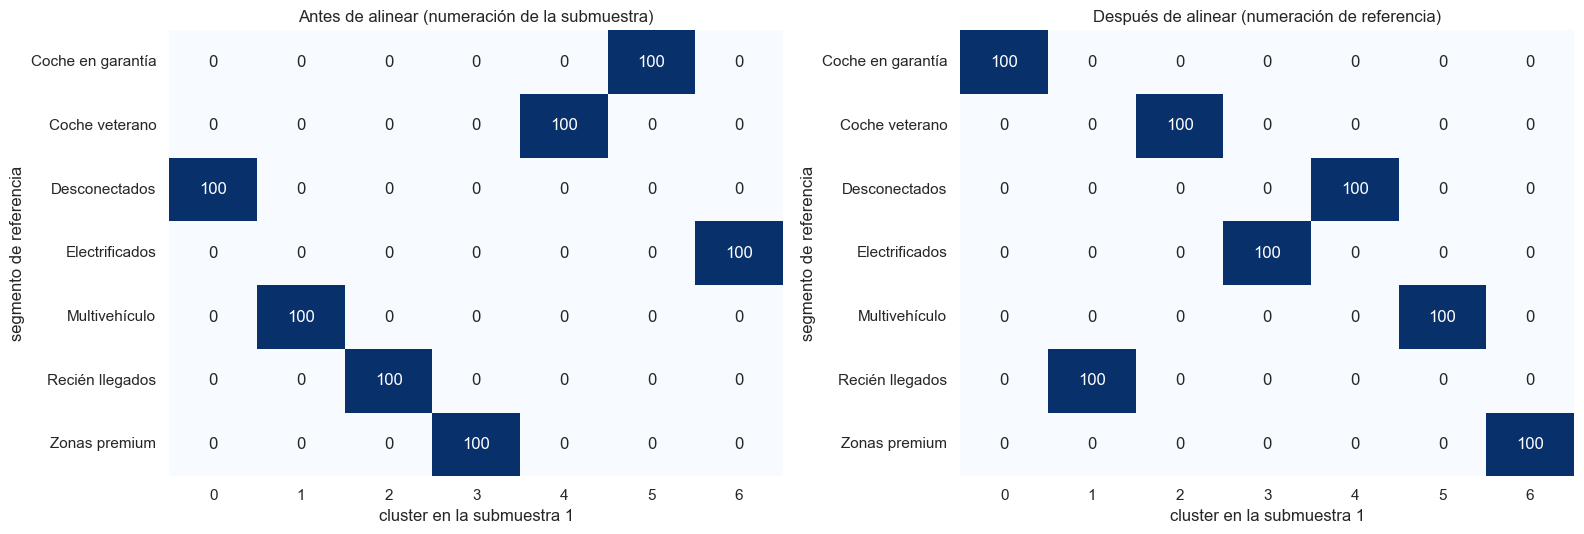

Coincidencia sin alinear: 0.0%
Coincidencia alineando  : 99.8%


In [4]:
def alinear(ref, etiquetas, mascara, k=K):
    """Renumera `etiquetas` para que cada cluster tome el número de su pareja en `ref`."""
    cont = (pd.crosstab(etiquetas[mascara], ref[mascara])
              .reindex(index=range(k), columns=range(k), fill_value=0).values)
    filas, columnas = linear_sum_assignment(-cont)   # el signo menos: queremos MAXIMIZAR coincidencias
    mapa = np.empty(k, dtype=int)
    mapa[filas] = columnas
    return mapa[etiquetas]

# Ejemplo con la primera submuestra
m_ej = modelo().fit(clientes[m0])
crudas = m_ej.predict(clientes)
alineadas = alinear(ref, crudas, m0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, lab, titulo in [(axes[0], crudas, "Antes de alinear (numeración de la submuestra)"),
                        (axes[1], alineadas, "Después de alinear (numeración de referencia)")]:
    t = pd.crosstab(pd.Series(ref[m0]).map(NOMBRES).rename("segmento de referencia"),
                    pd.Series(lab[m0]).rename("cluster en la submuestra 1"), normalize="index") * 100
    sns.heatmap(t, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax)
    ax.set_title(titulo)
plt.tight_layout()
plt.savefig(FIG / "07_alineacion_ejemplo.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Coincidencia sin alinear: {(crudas[m0] == ref[m0]).mean():.1%}")
print(f"Coincidencia alineando  : {(alineadas[m0] == ref[m0]).mean():.1%}")

El gráfico de la izquierda muestra el problema: los clientes de cada segmento de referencia sí se quedan juntos (en cada fila hay una celda con casi el 100 %), pero en una columna con otro número. Comparando los números sin más, la coincidencia sale del **0 %**, aunque **los grupos son prácticamente los mismos**. Después de alinear (derecha) aparece la diagonal y la coincidencia real es del **99,8 %**.

Sin este paso el Jackknife diría que la segmentación es un desastre cuando no lo es. Todo lo que viene a continuación usa etiquetas alineadas.

## 4. El Jackknife

Juntamos las piezas. Para cada una de las 20 submuestras: generamos la máscara, reentrenamos el pipeline entero con el 85 % de los clientes, predecimos el segmento de **todos** y alineamos la numeración con la referencia.

Guardamos dos matrices de 20 filas (una por submuestra) × 173.456 columnas (una por cliente):

- `L`: el segmento (ya alineado) que cada submuestra asigna a cada cliente.
- `M`: si el cliente estaba dentro de esa submuestra.

Y una función con las métricas:

- **Coincidencia por submuestra**: % de clientes que siguen en su segmento de referencia. Por separado para los que estaban dentro y para los que no.
- **ARI** (Adjusted Rand Index) entre cada submuestra y la referencia: 1 = misma partición; 0 = parecido al azar. A diferencia de la coincidencia, no necesita alinear.
- **Coincidencia por cliente**: de las submuestras en las que el cliente estaba, en qué fracción quedó en su segmento de referencia. **Es exactamente el "porcentaje de coincidencia de asignación" que pide el enunciado**, y se calcula para los clientes presentes en varias submuestras (todos lo están en 8 o más).
- **Jaccard por cluster**: para cada segmento, cuánto se parece el grupo de clientes de la submuestra al de referencia (intersección / unión). Es la medida de estabilidad por cluster más usada en la literatura (Hennig, 2007), con una escala orientativa: **≥ 0,85 muy estable**, 0,75-0,85 estable, 0,6-0,75 hay un patrón pero dudoso, < 0,5 el cluster se ha disuelto.

In [5]:
def jackknife(k=K, n_init=10, ref=None):
    """Reentrena el pipeline en N_SUBMUESTRAS submuestras y devuelve (ref, L, M)."""
    if ref is None:
        _, ref = entrenar_referencia(k, n_init)
    n = len(clientes)
    L = np.empty((N_SUBMUESTRAS, n), dtype=int)
    M = np.zeros((N_SUBMUESTRAS, n), dtype=bool)
    for r in range(N_SUBMUESTRAS):
        dentro = submuestra(r)
        m = modelo(k, n_init).fit(clientes[dentro])
        L[r] = alinear(ref, m.predict(clientes), dentro, k)
        M[r] = dentro
    return ref, L, M


def metricas(ref, L, M, k=K):
    """Coincidencia por submuestra, por cliente y Jaccard por cluster."""
    ok = L == ref
    por_sub = pd.DataFrame({
        "coincidencia (dentro)": (ok & M).sum(1) / M.sum(1),
        "coincidencia (fuera)": (ok & ~M).sum(1) / (~M).sum(1),
        "ARI": [adjusted_rand_score(ref[M[r]], L[r][M[r]]) for r in range(len(L))],
    }, index=pd.RangeIndex(1, len(L) + 1, name="submuestra"))
    por_cliente = (ok & M).sum(0) / M.sum(0)
    jaccard = np.array([
        np.mean([((ref == c) & (L[r] == c) & M[r]).sum() / (((ref == c) | (L[r] == c)) & M[r]).sum()
                 for r in range(len(L))])
        for c in range(k)])
    return por_sub, por_cliente, jaccard


t0 = time.time()
_, L10, M10 = jackknife(n_init=10, ref=ref)
sub10, cli10, jac10 = metricas(ref, L10, M10)
print(f"20 reentrenamientos en {time.time() - t0:.0f} s")
print(f"Cada cliente está dentro de entre {M10.sum(0).min()} y {M10.sum(0).max()} submuestras "
      f"(mediana {np.median(M10.sum(0)):.0f})")

20 reentrenamientos en 56 s
Cada cliente está dentro de entre 8 y 20 submuestras (mediana 17)


## 5. Primer resultado: estabilidad submuestra a submuestra

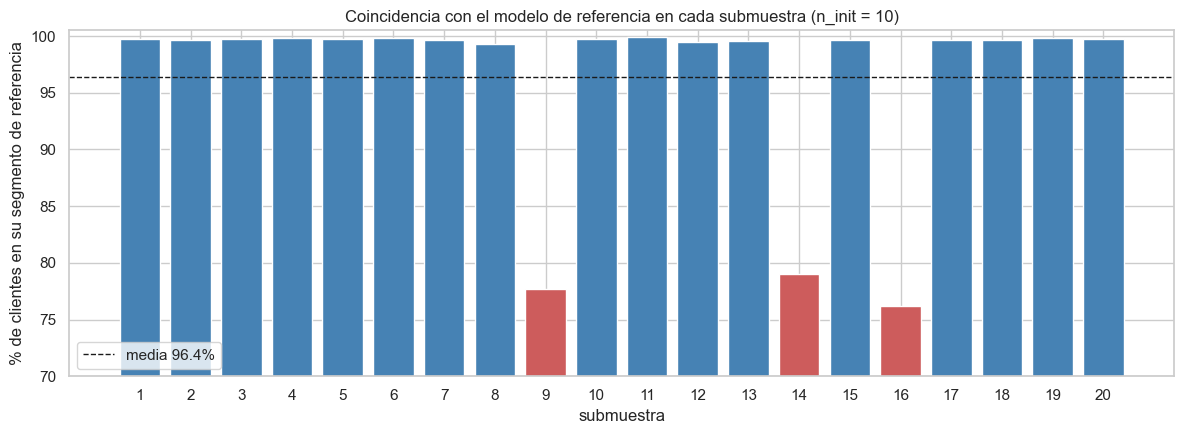

submuestra,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
coincidencia (dentro),0.9978,0.9969,0.9974,0.9981,0.9970,0.9981,0.9968,0.9928,0.7765,0.9971,0.9989,0.9949,0.9955,0.7904,0.9965,0.7616,0.9970,0.9962,0.9981,0.9977
coincidencia (fuera),0.9980,0.9974,0.9975,0.9975,0.9967,0.9983,0.9968,0.9927,0.7724,0.9976,0.9991,0.9945,0.9955,0.7903,0.9970,0.7559,0.9975,0.9963,0.9981,0.9977
ARI,0.9941,0.9917,0.9933,0.9949,0.9921,0.9951,0.9915,0.9807,0.6395,0.9924,0.9972,0.9886,0.9880,0.6444,0.9908,0.6567,0.9921,0.9902,0.9956,0.9939


In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
colores = ["indianred" if v < 0.97 else "steelblue" for v in sub10["coincidencia (dentro)"]]
ax.bar(sub10.index, sub10["coincidencia (dentro)"] * 100, color=colores)
ax.axhline(sub10["coincidencia (dentro)"].mean() * 100, color="k", ls="--", lw=1,
           label=f"media {sub10['coincidencia (dentro)'].mean():.1%}")
ax.set_ylim(70, 100.5)
ax.set_xticks(sub10.index)
ax.set_xlabel("submuestra")
ax.set_ylabel("% de clientes en su segmento de referencia")
ax.set_title("Coincidencia con el modelo de referencia en cada submuestra (n_init = 10)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG / "07_coincidencia_por_submuestra_ninit10.png", dpi=150, bbox_inches="tight")
plt.show()

sub10.round(4).T

Esto es lo primero que encontramos, y no es lo que esperábamos:

- **17 de las 20 submuestras reproducen el modelo casi a la perfección** (entre el 99,3 % y el 99,9 % de los clientes en su segmento).
- Pero **tres (la 9, la 14 y la 16) se desvían mucho**: solo entre el 76 % y el 79 % de los clientes se quedan en su segmento.

Así que la media del 96,4 % esconde algo importante: la inestabilidad **no es un ruido repartido entre todos los clientes**, sino que de vez en cuando el modelo entero **salta a otra segmentación distinta**. Eso es mucho más preocupante que un poco de ruido en los bordes, porque significa que, según qué clientes haya en los datos, marketing podría recibir segmentos diferentes.

Las columnas "fuera" (clientes que no estaban en la submuestra) se comportan igual que las de "dentro": el modelo asigna a los clientes nuevos de forma tan consistente como a los que ha visto.

## 6. ¿Qué pasa en las submuestras que fallan?

Miramos dentro de la peor: para cada segmento de referencia (filas), a qué segmento manda esa submuestra a sus clientes (columnas). Si todo fuera estable, veríamos una diagonal de 100.

Submuestras que se desvían: [9, 14, 16]


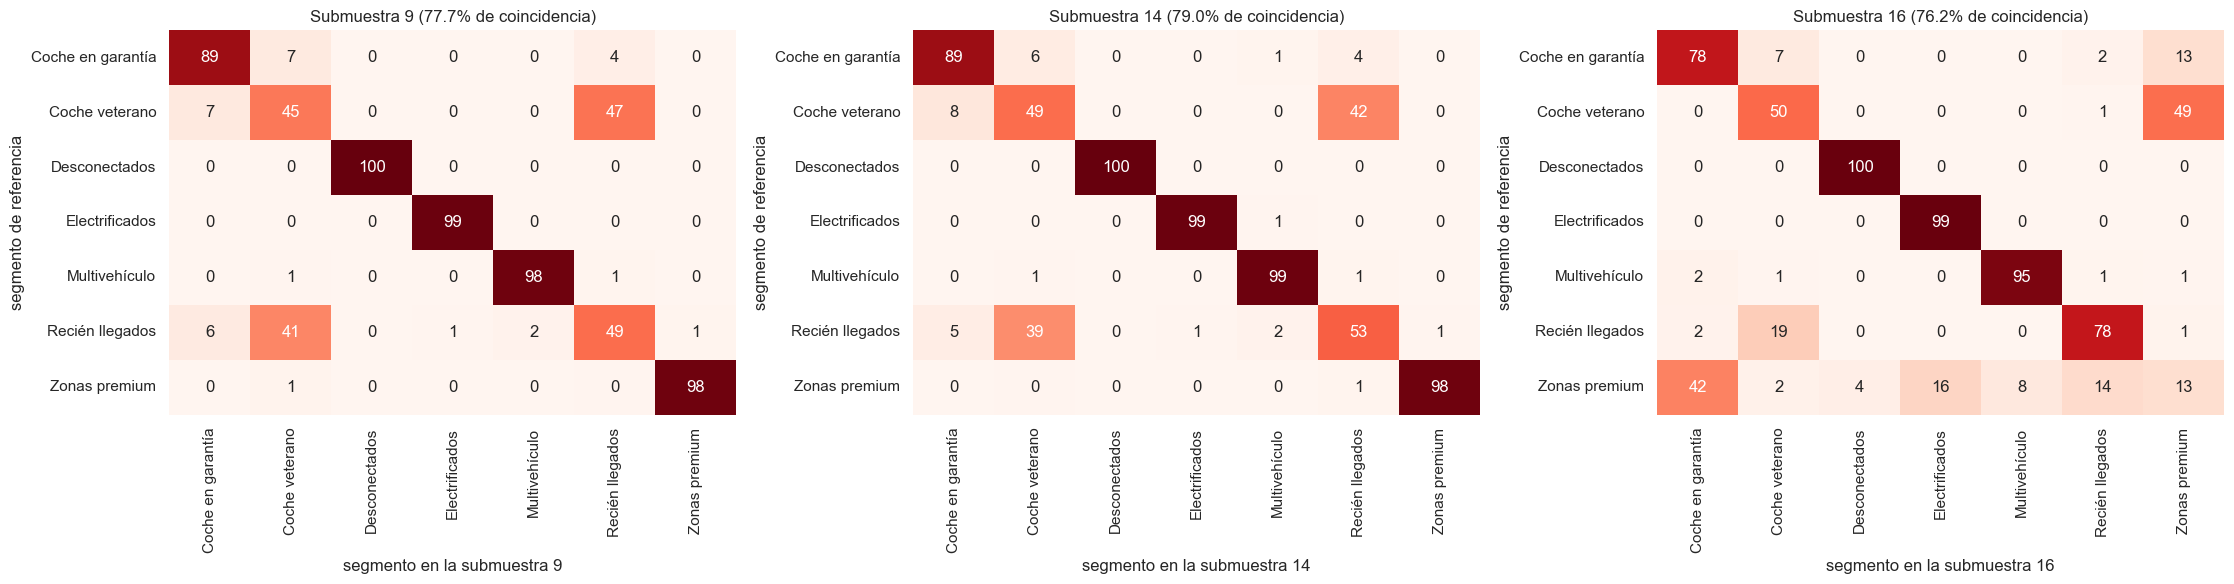

In [7]:
malas = sub10.index[sub10["coincidencia (dentro)"] < 0.97].tolist()
print("Submuestras que se desvían:", malas)

fig, axes = plt.subplots(1, len(malas), figsize=(7.5 * len(malas), 6))
for ax, s in zip(np.atleast_1d(axes), malas):
    r = s - 1
    t = pd.crosstab(pd.Series(ref[M10[r]]).map(NOMBRES).rename("segmento de referencia"),
                    pd.Series(L10[r][M10[r]]).map(NOMBRES).rename(f"segmento en la submuestra {s}"),
                    normalize="index") * 100
    sns.heatmap(t, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar=False, ax=ax)
    ax.set_title(f"Submuestra {s} ({sub10.loc[s, 'coincidencia (dentro)']:.1%} de coincidencia)")
plt.tight_layout()
plt.savefig(FIG / "07_submuestras_que_fallan.png", dpi=150, bbox_inches="tight")
plt.show()

Las tres submuestras no fallan de la misma forma, pero el patrón es claro:

- **Submuestras 9 y 14:** cinco segmentos se mantienen casi intactos (Desconectados, Electrificados, Multivehículo y Zonas premium por encima del 98 %; Coche en garantía alrededor del 89 %). Lo que cambia es la frontera entre **Coche veterano** y **Recién llegados**: cada uno manda a la mitad de sus clientes al otro. Siguen existiendo dos grupos, pero cortados por otro sitio.
- **Submuestra 16:** desaparece **Zonas premium** (solo el 13 % de sus clientes se queda; el resto se reparte, sobre todo a Coche en garantía) y su hueco lo ocupa la mitad de **Coche veterano**, que se parte en dos.

En los tres casos, los segmentos implicados son los que se definen por variables **continuas** (antigüedad del coche, meses como cliente, riqueza de la zona), no los que se definen por un rasgo nítido (no tener coche activo, tener un eléctrico, tener muchos vehículos).

## 7. Diagnóstico: ¿el problema es de los datos o del algoritmo?

Hay dos explicaciones posibles para esas submuestras, y llevan a recomendaciones opuestas:

1. **Los datos tienen dos estructuras igual de buenas.** Quitar un 15 % de clientes basta para que la otra pase a ser la mejor. En ese caso los segmentos afectados **no son fiables** y habría que replantearlos.
2. **El algoritmo no ha encontrado la mejor solución.** K-Means solo garantiza encontrar un óptimo *local*: según dónde arranquen los centros, puede quedarse en una solución peor. Con 10 arranques normalmente basta, pero no siempre. En ese caso los segmentos **sí son fiables** y lo que hay que cambiar es el entrenamiento.

Para distinguirlas, reentrenamos las submuestras que fallan de tres maneras y comparamos la **inercia** (lo que K-Means intenta minimizar: cuanto más baja, mejor solución):

- con `n_init = 10`, como el pipeline del equipo;
- con `n_init = 50`, cinco veces más arranques;
- arrancando **directamente desde la solución de referencia** (los centroides de los segmentos de referencia calculados sobre esa submuestra).

Si la solución de referencia tiene **menos** inercia que la que encontró `n_init = 10`, es que el algoritmo se quedó en un óptimo peor: explicación 2.

In [8]:
filas = []
for s in malas:
    dentro = submuestra(s - 1)
    prep = pl.build_preprocessor().fit(clientes[dentro])
    Xs = prep.transform(clientes[dentro])
    centros_ref = np.vstack([Xs[ref[dentro] == c].mean(0) for c in range(K)])
    versiones = {
        "n_init = 10 (pipeline actual)": KMeans(K, n_init=10, random_state=config.RANDOM_STATE),
        "n_init = 50": KMeans(K, n_init=50, random_state=config.RANDOM_STATE),
        "arrancando en la referencia": KMeans(K, init=centros_ref, n_init=1),
    }
    for nombre, km in versiones.items():
        km.fit(Xs)
        lab = alinear(ref[dentro], km.labels_, np.ones(dentro.sum(), dtype=bool))
        filas.append({"submuestra": s, "entrenamiento": nombre, "inercia": km.inertia_,
                      "coincidencia con la referencia": (lab == ref[dentro]).mean()})

diagnostico = pd.DataFrame(filas).set_index(["submuestra", "entrenamiento"])
diagnostico.style.format({"inercia": "{:,.0f}", "coincidencia con la referencia": "{:.1%}"})

El diagnóstico es concluyente: **el problema es del algoritmo, no de los datos.**

- En las tres submuestras, la solución que encontró `n_init = 10` tiene **más inercia** (entre 944.000 y 954.000) que la solución de referencia (unos 933.000). Es decir, es una solución **peor**: K-Means se quedó atascado en un óptimo local.
- Con **`n_init = 50`**, K-Means encuentra en las tres la solución de **menor inercia**, y esa solución es **la de referencia** (más del 99 % de coincidencia).
- Arrancando directamente desde la referencia se llega a la misma inercia que con `n_init = 50`. No existe una segmentación alternativa igual de buena: la nuestra es la mejor.

En la práctica: con 10 arranques, en aproximadamente **una de cada siete submuestras** (3 de 20) ninguno de los 10 arranques cae cerca de la mejor solución. Subir a 50 lo resuelve, y el coste es pequeño: cada entrenamiento pasa de unos 2-3 segundos a unos 7.

## 8. Jackknife definitivo con `n_init = 50`

Repetimos el experimento con 50 arranques. Antes comprobamos que el modelo de referencia no cambia: si con 50 arranques saliera otra segmentación, todo el trabajo del reto 4 estaría construido sobre la solución equivocada.

In [9]:
modelo_ref50, ref50 = entrenar_referencia(n_init=50)
print(f"Referencia con n_init=50 frente a n_init=10:")
print(f"  inercia        : {modelo_ref50.named_steps['kmeans'].inertia_:,.0f}  vs  "
      f"{modelo_ref.named_steps['kmeans'].inertia_:,.0f}")
print(f"  mismo segmento : {(ref50 == ref).mean():.3%} de los clientes")
print(f"  ARI            : {adjusted_rand_score(ref, ref50):.4f}")

Referencia con n_init=50 frente a n_init=10:
  inercia        : 1,098,056  vs  1,098,057
  mismo segmento : 99.787% de los clientes
  ARI            : 0.9943


El modelo de referencia apenas cambia: **el 99,8 % de los clientes sigue en el mismo segmento** (ARI 0,994). Solo cambian de segmento unos 370 clientes de 173.456. Los segmentos, sus nombres y el análisis del reto 4 siguen siendo válidos.

20 reentrenamientos con n_init=50 en 199 s


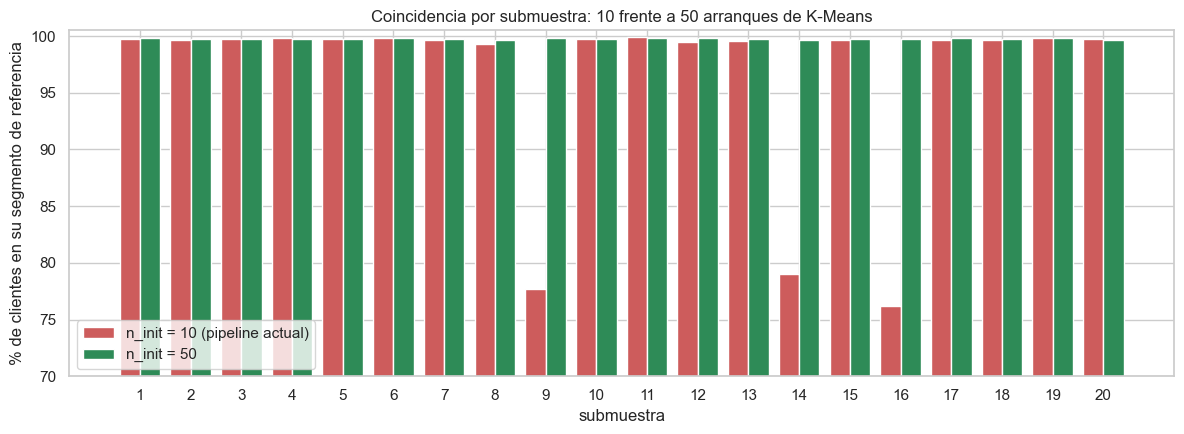

,n_init = 10,n_init = 50
coincidencia media (dentro),0.9638,0.9976
coincidencia mínima (dentro),0.7616,0.9962
coincidencia media (fuera),0.9633,0.9976
ARI medio,0.9401,0.9938


In [10]:
t0 = time.time()
_, L50, M50 = jackknife(n_init=50, ref=ref50)
sub50, cli50, jac50 = metricas(ref50, L50, M50)
print(f"20 reentrenamientos con n_init=50 en {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(12, 4.5))
ancho = 0.4
ax.bar(sub10.index - ancho / 2, sub10["coincidencia (dentro)"] * 100, ancho,
       color="indianred", label="n_init = 10 (pipeline actual)")
ax.bar(sub50.index + ancho / 2, sub50["coincidencia (dentro)"] * 100, ancho,
       color="seagreen", label="n_init = 50")
ax.set_ylim(70, 100.5)
ax.set_xticks(sub50.index)
ax.set_xlabel("submuestra")
ax.set_ylabel("% de clientes en su segmento de referencia")
ax.set_title("Coincidencia por submuestra: 10 frente a 50 arranques de K-Means")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG / "07_coincidencia_por_submuestra.png", dpi=150, bbox_inches="tight")
plt.show()

resumen_global = pd.DataFrame({
    "n_init = 10": [sub10.iloc[:, 0].mean(), sub10.iloc[:, 0].min(), sub10.iloc[:, 1].mean(), sub10.ARI.mean()],
    "n_init = 50": [sub50.iloc[:, 0].mean(), sub50.iloc[:, 0].min(), sub50.iloc[:, 1].mean(), sub50.ARI.mean()],
}, index=["coincidencia media (dentro)", "coincidencia mínima (dentro)",
          "coincidencia media (fuera)", "ARI medio"])
resumen_global.round(4)

Con 50 arranques las tres submuestras problemáticas desaparecen:

| | n_init = 10 | n_init = 50 |
|---|---|---|
| Coincidencia media | 96,4 % | **99,8 %** |
| Peor submuestra | 76,2 % | **99,6 %** |
| ARI medio con la referencia | 0,940 | **0,994** |

Ahora **las 20 submuestras reproducen la referencia entre el 99,6 % y el 99,9 %**, y la coincidencia de los clientes que se quedaron fuera es la misma (99,8 %). La segmentación es reproducible.

A partir de aquí todo el análisis usa el Jackknife con `n_init = 50`.

### 8.1 ¿Coinciden también las submuestras entre sí?

Hasta ahora hemos comparado cada submuestra con la referencia. Para asegurarnos de que la referencia no es "la rara", comparamos también **todas las submuestras entre sí** (190 parejas), con el ARI sobre los clientes que estaban en las dos.

In [11]:
aris = []
for i in range(N_SUBMUESTRAS):
    for j in range(i + 1, N_SUBMUESTRAS):
        comunes = M50[i] & M50[j]
        aris.append(adjusted_rand_score(L50[i][comunes], L50[j][comunes]))
aris = np.array(aris)
print(f"{len(aris)} parejas de submuestras · ARI medio {aris.mean():.4f} · mínimo {aris.min():.4f} · máximo {aris.max():.4f}")

190 parejas de submuestras · ARI medio 0.9917 · mínimo 0.9860 · máximo 0.9962


Las submuestras también coinciden entre sí con un ARI muy alto. Así que no es que todas se parezcan a una referencia "rara": las 20 submuestras y la referencia encuentran **la misma segmentación**.

## 9. Estabilidad por cliente

Para cada cliente: de las submuestras en las que estaba, ¿en qué porcentaje quedó en su segmento de referencia? Agrupamos el resultado en tramos que se leen fácil. Llamamos **"saltadores"** a los clientes con una coincidencia por debajo del 80 %: aquellos a los que, al menos una de cada cinco veces, el modelo manda a otro segmento.

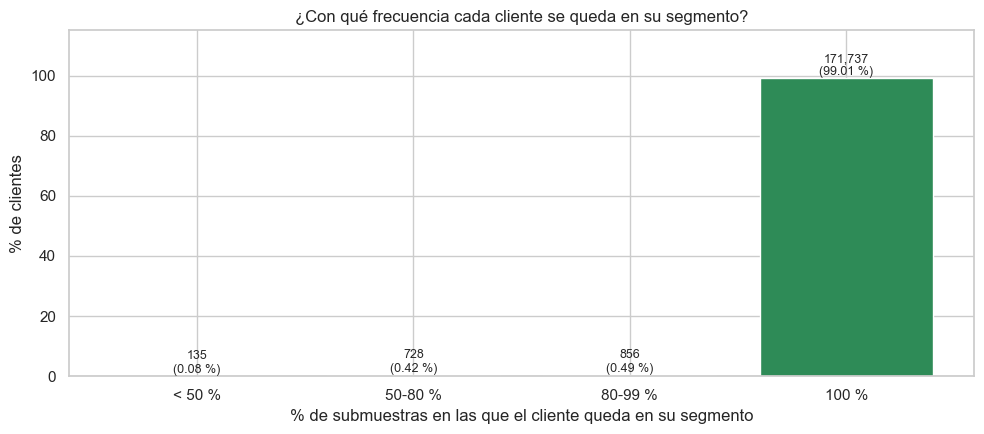

Saltadores (coincidencia < 80 %): 863 clientes (0.50%)


,clientes,%
coincidencia del cliente,,
< 50 %,135,0.08
50-80 %,728,0.42
80-99 %,856,0.49
100 %,171737,99.01


In [12]:
# Cortes cerrados por la izquierda: [0, 50 %), [50 %, 80 %), [80 %, 100 %) y 100 % exacto.
# Así "< 80 %" es exactamente la definición de saltador.
tramos = pd.cut(cli50, [0, 0.5, 0.8, 1.0, 1.01], right=False,
                labels=["< 50 %", "50-80 %", "80-99 %", "100 %"])
por_tramo = pd.Series(tramos).value_counts().reindex(tramos.categories).to_frame("clientes")
por_tramo["%"] = (por_tramo.clientes / len(cli50) * 100).round(2)
por_tramo.index.name = "coincidencia del cliente"

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["indianred", "darkorange", "khaki", "seagreen"]
ax.bar(por_tramo.index.astype(str), por_tramo["%"], color=colores)
for i, (n, p) in enumerate(zip(por_tramo.clientes, por_tramo["%"])):
    ax.text(i, p + 1, f"{n:,}\n({p:.2f} %)", ha="center", fontsize=9)
ax.set_ylim(0, 115)
ax.set_xlabel("% de submuestras en las que el cliente queda en su segmento")
ax.set_ylabel("% de clientes")
ax.set_title("¿Con qué frecuencia cada cliente se queda en su segmento?")
plt.tight_layout()
plt.savefig(FIG / "07_coincidencia_por_cliente.png", dpi=150, bbox_inches="tight")
plt.show()

saltadores = cli50 < 0.8
print(f"Saltadores (coincidencia < 80 %): {saltadores.sum():,} clientes ({saltadores.mean():.2%})")
por_tramo

- **El 99,0 % de los clientes queda en su segmento en el 100 % de las submuestras** en las que aparece. Para ellos la asignación es completamente estable.
- **Solo 863 clientes (el 0,50 %) son "saltadores"**, con una coincidencia por debajo del 80 %.
- Y solo el 0,08 % baja del 50 %: clientes a los que el modelo manda más veces a otro segmento que al suyo.
- El tramo 80-99 % lo forman sobre todo clientes que fallan en **una sola** submuestra de las ~17 en las que están.

Para comparar: con `n_init = 10` solo el 57,9 % de los clientes era estable en todas las submuestras, porque cada una de las tres submuestras malas "movía" a casi una cuarta parte de la cartera.

## 10. Estabilidad por segmento

La pregunta del enunciado: **¿hay algún segmento especialmente inestable?** Para cada segmento calculamos el Jaccard medio, la coincidencia media de sus clientes y cuántos saltadores tiene.

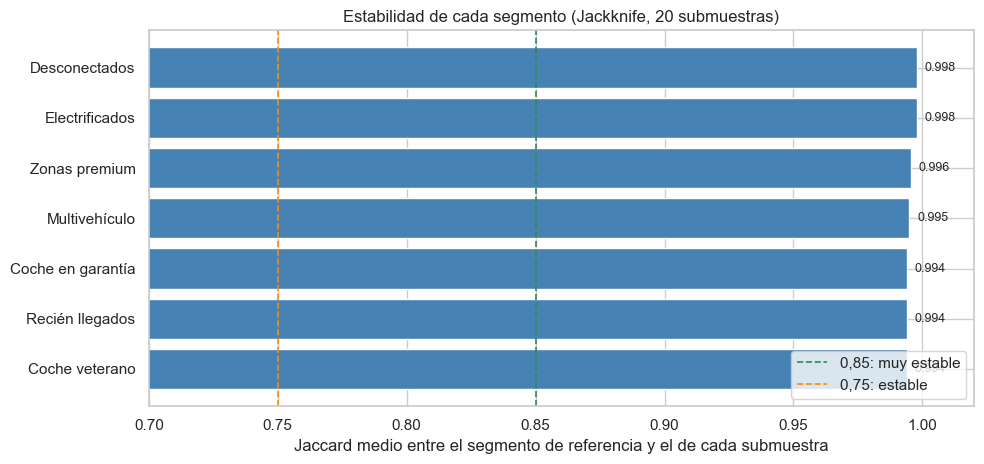

,segmento,clientes,Jaccard medio,coincidencia media,saltadores,% saltadores
cluster,,,,,,
2,Coche veterano,"31,589",0.994,99.73%,176,0.56 %
1,Recién llegados,"31,822",0.994,99.69%,208,0.65 %
0,Coche en garantía,"41,751",0.994,99.68%,281,0.67 %
5,Multivehículo,"15,395",0.995,99.76%,73,0.47 %
6,Zonas premium,"9,689",0.996,99.82%,38,0.39 %
3,Electrificados,"27,562",0.998,99.89%,63,0.23 %
4,Desconectados,"15,648",0.998,99.91%,24,0.15 %


In [13]:
por_segmento = pd.DataFrame({
    "segmento": [NOMBRES[c] for c in range(K)],
    "clientes": np.bincount(ref50),
    "Jaccard medio": jac50,
    "coincidencia media": pd.Series(cli50).groupby(ref50).mean().values,
    "saltadores": pd.Series(saltadores).groupby(ref50).sum().values,
})
por_segmento["% saltadores"] = por_segmento.saltadores / por_segmento.clientes * 100
por_segmento.index.name = "cluster"
por_segmento = por_segmento.sort_values("Jaccard medio")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(por_segmento.segmento, por_segmento["Jaccard medio"], color="steelblue")
ax.axvline(0.85, color="seagreen", ls="--", lw=1.2, label="0,85: muy estable")
ax.axvline(0.75, color="darkorange", ls="--", lw=1.2, label="0,75: estable")
for i, v in enumerate(por_segmento["Jaccard medio"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.7, 1.02)
ax.set_xlabel("Jaccard medio entre el segmento de referencia y el de cada submuestra")
ax.set_title("Estabilidad de cada segmento (Jackknife, 20 submuestras)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "07_estabilidad_por_segmento.png", dpi=150, bbox_inches="tight")
plt.show()

por_segmento.style.format({"Jaccard medio": "{:.3f}", "coincidencia media": "{:.2%}",
                           "% saltadores": "{:.2f} %", "clientes": "{:,}"})

**Ningún segmento es inestable.** Los siete tienen un Jaccard medio de **0,994 o más**, muy por encima del umbral de "muy estable" (0,85). Aun así, dentro de esa estabilidad hay un orden claro, y tiene explicación:

| Más estables | Menos estables (aunque muy estables) |
|---|---|
| **Desconectados** (0,15 % de saltadores) y **Electrificados** (0,23 %) | **Coche en garantía** (0,67 %), **Recién llegados** (0,65 %) y **Coche veterano** (0,56 %) |
| Se definen por un rasgo **nítido**: no tener ningún coche activo, o tener un eléctrico/enchufable. Un cliente lo cumple o no lo cumple; no hay término medio | Se definen por variables **continuas**: antigüedad del coche, meses como cliente y visitas en garantía. Un coche de 4 años no es "nuevo" ni "viejo": está en medio, y la frontera entre estos tres segmentos es un corte en un continuo |

Es el mismo patrón que vimos en las submuestras que fallaban con `n_init = 10`: cuando hay inestabilidad, aparece en la zona del **ciclo de vida del coche**, no en los segmentos con un rasgo diferencial claro.

## 11. ¿Hacia dónde saltan?

Cada vez que un cliente queda en un segmento distinto del de referencia, apuntamos el par **segmento de origen → segmento de destino**. La tabla dice, de todos los "saltos" que salen de un segmento, qué porcentaje va a cada destino. Y la columna de la derecha, cuántos saltos hay en total, para no dar importancia a porcentajes sobre muy pocos casos.

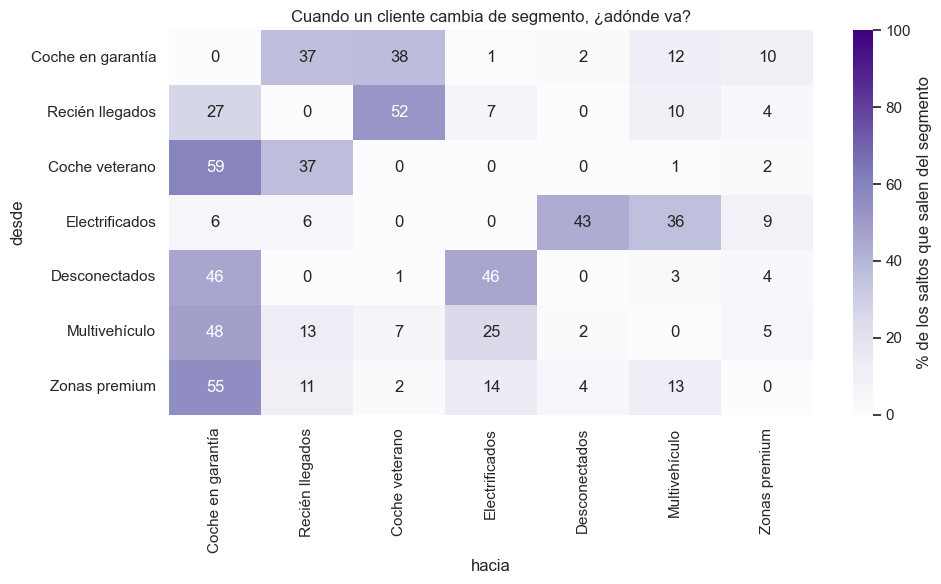

hacia,Coche en garantía,Recién llegados,Coche veterano,Electrificados,Desconectados,Multivehículo,Zonas premium,saltos totales
desde,,,,,,,,
Coche en garantía,0,839,861,24,44,280,240,2288
Recién llegados,454,0,893,118,0,176,62,1703
Coche veterano,854,537,0,0,0,19,32,1442
Electrificados,31,30,1,0,233,193,49,537
Desconectados,108,0,3,108,0,7,9,235
Multivehículo,302,81,42,156,12,0,34,627
Zonas premium,162,33,6,41,13,37,0,292


In [14]:
fallos = (L50 != ref50) & M50
r_idx, c_idx = np.where(fallos)
saltos = pd.crosstab(pd.Series(ref50[c_idx]).map(NOMBRES).rename("desde"),
                     pd.Series(L50[r_idx, c_idx]).map(NOMBRES).rename("hacia"))
orden = [NOMBRES[c] for c in range(K)]
saltos = saltos.reindex(index=orden, columns=orden, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(saltos.div(saltos.sum(1), axis=0) * 100, annot=True, fmt=".0f", cmap="Purples",
            vmin=0, vmax=100, cbar_kws={"label": "% de los saltos que salen del segmento"}, ax=ax)
ax.set_title("Cuando un cliente cambia de segmento, ¿adónde va?")
plt.tight_layout()
plt.savefig(FIG / "07_saltos_entre_segmentos.png", dpi=150, bbox_inches="tight")
plt.show()

saltos.assign(**{"saltos totales": saltos.sum(1)})

Los saltos no van a cualquier sitio. Hay un **triángulo** que concentra la mayoría:

- **Coche en garantía ↔ Coche veterano ↔ Recién llegados.** Los tres segmentos del ciclo de vida del coche intercambian clientes entre sí. Un cliente con un coche de 4-5 años y alguna visita en garantía puede estar a la vez cerca de "Coche en garantía" (ha usado la garantía), de "Coche veterano" (el coche ya tiene años) y de "Recién llegados" (si lleva poco como cliente).

Y dos flujos más pequeños, con su lógica:

- **Multivehículo → Coche en garantía / Electrificados:** clientes con 2-3 vehículos, justo en el límite de lo que el modelo considera "muchos".
- **Electrificados → Desconectados / Multivehículo:** pocos casos en números absolutos (son saltos raros desde un segmento muy estable), de clientes electrificados con algún rasgo de los otros dos.

Lo que **no** aparece: saltos entre segmentos que no tienen nada que ver (por ejemplo, de Desconectados a Recién llegados hay cero). Los clientes solo dudan entre segmentos **vecinos**.

## 12. ¿Por qué saltan? La distancia a la frontera

K-Means asigna cada cliente al centroide más cercano. Un cliente que está casi a la misma distancia de dos centroides está **en la frontera** entre dos segmentos, y basta un pequeño movimiento de los centroides (que es lo que provoca quitar un 15 % de clientes) para que cruce al otro lado.

Lo medimos con el **margen**: la distancia al segundo centroide más cercano menos la distancia al más cercano, en el modelo de referencia. Un margen cercano a 0 = cliente en la frontera. Dividimos a los clientes en diez grupos iguales (deciles) según su margen y miramos cuántos saltadores hay en cada uno.

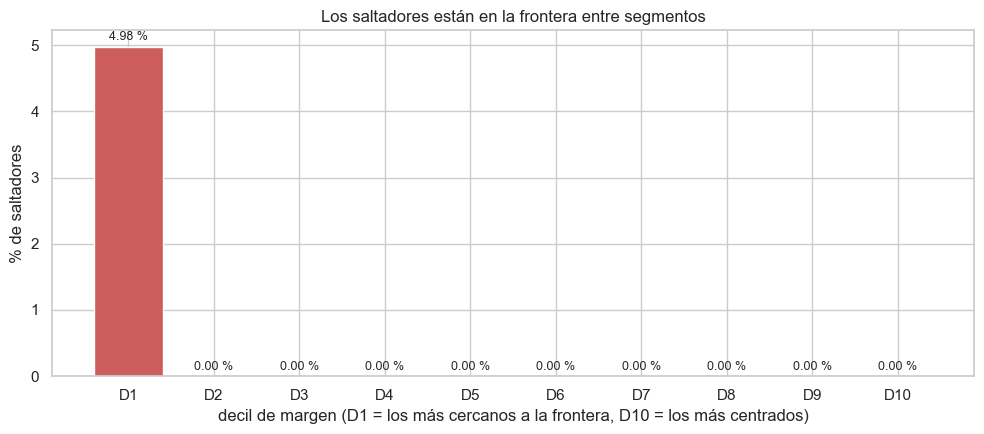

,margen mediano,% saltadores,coincidencia media
decil de margen (D1 = frontera),,,
D1,0.063,4.98 %,97.59%
D2,0.193,0.00 %,100.00%
D3,0.334,0.00 %,100.00%
D4,0.487,0.00 %,100.00%
D5,0.656,0.00 %,100.00%
D6,0.823,0.00 %,100.00%
D7,0.983,0.00 %,100.00%
D8,1.156,0.00 %,100.00%
D9,1.351,0.00 %,100.00%


In [15]:
X_ref = modelo_ref50.named_steps["prep"].transform(clientes)
dist = np.sort(modelo_ref50.named_steps["kmeans"].transform(X_ref), axis=1)
margen = dist[:, 1] - dist[:, 0]
decil = pd.qcut(margen, 10, labels=[f"D{i}" for i in range(1, 11)])

por_decil = pd.DataFrame({
    "margen mediano": pd.Series(margen).groupby(decil, observed=True).median(),
    "% saltadores": pd.Series(saltadores).groupby(decil, observed=True).mean() * 100,
    "coincidencia media": pd.Series(cli50).groupby(decil, observed=True).mean(),
})
por_decil.index.name = "decil de margen (D1 = frontera)"

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(por_decil.index.astype(str), por_decil["% saltadores"], color="indianred")
for i, v in enumerate(por_decil["% saltadores"]):
    ax.text(i, v + 0.1, f"{v:.2f} %", ha="center", fontsize=9)
ax.set_xlabel("decil de margen (D1 = los más cercanos a la frontera, D10 = los más centrados)")
ax.set_ylabel("% de saltadores")
ax.set_title("Los saltadores están en la frontera entre segmentos")
plt.tight_layout()
plt.savefig(FIG / "07_margen_vs_estabilidad.png", dpi=150, bbox_inches="tight")
plt.show()

por_decil.style.format({"margen mediano": "{:.3f}", "% saltadores": "{:.2f} %", "coincidencia media": "{:.2%}"})

Este es el resultado más claro de todo el análisis: **los 863 saltadores están todos en el primer decil**, el 10 % de clientes más cercano a una frontera. Del decil 2 al 10, **ningún cliente cambia nunca de segmento** (coincidencia del 100 %).

Esto responde al *por qué*: un cliente salta cuando está prácticamente a la misma distancia de dos centroides. No es algo raro de esos clientes ni un error de datos; es la consecuencia natural de cortar una nube de clientes continua en siete trozos.

Y tiene una aplicación directa: **el margen es una "nota de confianza" de la asignación de cada cliente**, que se puede calcular para cualquier cliente sin repetir el Jackknife.

### 12.1 ¿Cómo son los saltadores?

Comparamos a los saltadores con el resto en las variables del modelo, en unidades reales.

In [16]:
perfil_vars = {
    "main_vehicle_age": "antigüedad del coche (años, mediana)",
    "tenure_months": "meses como cliente (mediana)",
    "workshop_visits_mean": "visitas en garantía por coche (mediana)",
    "n_vehicles": "nº de vehículos (mediana)",
}
perfil = clientes.assign(grupo=np.where(saltadores, "saltadores", "resto")).groupby("grupo")
tabla = perfil[list(perfil_vars)].median().T.rename(index=perfil_vars)
extra = (perfil[["tenure_is_default", "has_telemetry", "is_ch"]].mean().T * 100).rename(index={
    "tenure_is_default": "% con antigüedad por defecto (36 meses)",
    "has_telemetry": "% con telemetría",
    "is_ch": "% en Suiza"})
pd.concat([tabla, extra]).round(2)[["saltadores", "resto"]]

grupo,saltadores,resto
"antigüedad del coche (años, mediana)",4.57,4.24
meses como cliente (mediana),36.00,36.00
visitas en garantía por coche (mediana),2.00,1.40
nº de vehículos (mediana),1.00,1.00
% con antigüedad por defecto (36 meses),16.92,12.19
% con telemetría,61.07,59.57
% en Suiza,70.45,66.14


Los saltadores no son un tipo de cliente especial: se parecen mucho al resto. Solo hay diferencias suaves, que encajan con el triángulo del ciclo de vida:

- Su coche es algo más viejo y han usado un poco más la garantía. Están justo entre "coche reciente con poca garantía usada" y "coche con años".
- Tienen algo más de antigüedad por defecto (36 meses): para ellos, una de las variables que separa estos segmentos es poco fiable, y eso les deja más cerca de la frontera.

## 13. Extra: ¿qué pasaría con k = 6 o k = 8?

El Jackknife también sirve para revisar la elección de k del reto 3. Repetimos exactamente el mismo experimento (20 submuestras, 15 %, `n_init = 50`) con un cluster menos y uno más.

k = 6: 189 s


k = 8: 247 s


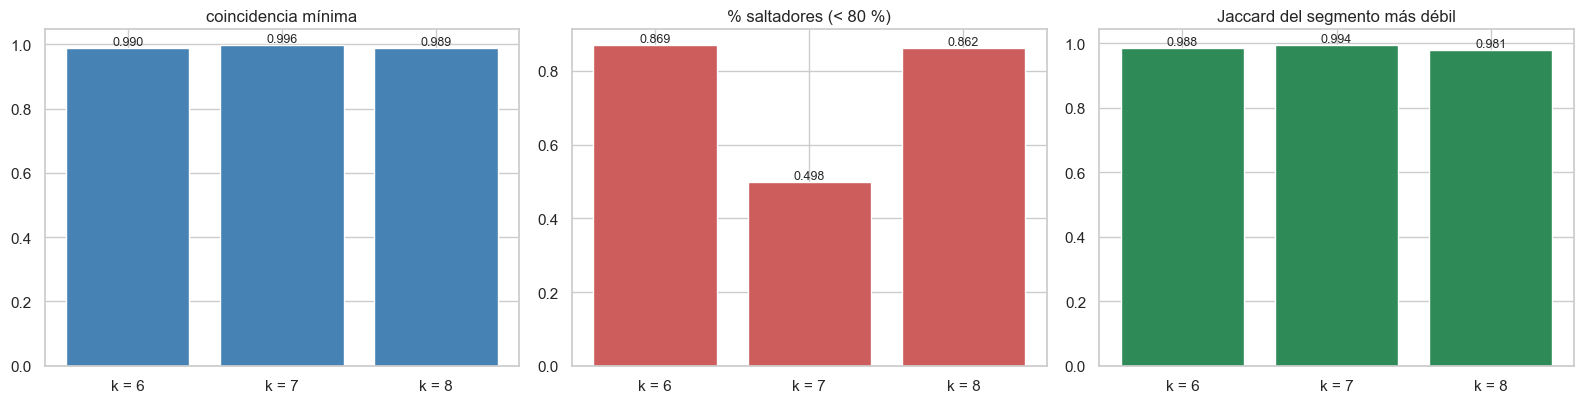

,k = 6,k = 7,k = 8
coincidencia media,0.9950,0.9976,0.9948
coincidencia mínima,0.9895,0.9962,0.9888
ARI medio,0.9870,0.9938,0.9876
% clientes 100 % estables,98.0087,99.0090,97.8536
% saltadores (< 80 %),0.8694,0.4975,0.8625
Jaccard del segmento más débil,0.9875,0.9940,0.9808


In [17]:
comparativa = {}
referencias = {K: ref50}
for k in [6, 7, 8]:
    if k == K:
        s, c, j = sub50, cli50, jac50
    else:
        t0 = time.time()
        r_k, L_k, M_k = jackknife(k, n_init=50)
        s, c, j = metricas(r_k, L_k, M_k, k)
        referencias[k] = r_k
        print(f"k = {k}: {time.time() - t0:.0f} s")
    comparativa[f"k = {k}"] = {
        "coincidencia media": s.iloc[:, 0].mean(),
        "coincidencia mínima": s.iloc[:, 0].min(),
        "ARI medio": s.ARI.mean(),
        "% clientes 100 % estables": (c == 1).mean() * 100,
        "% saltadores (< 80 %)": (c < 0.8).mean() * 100,
        "Jaccard del segmento más débil": j.min(),
    }
comparativa = pd.DataFrame(comparativa)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, fila, color in zip(axes, ["coincidencia mínima", "% saltadores (< 80 %)", "Jaccard del segmento más débil"],
                           ["steelblue", "indianred", "seagreen"]):
    vals = comparativa.loc[fila]
    ax.bar(vals.index, vals.values, color=color)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(fila)
plt.tight_layout()
plt.savefig(FIG / "07_estabilidad_k6_k7_k8.png", dpi=150, bbox_inches="tight")
plt.show()

comparativa.round(4)

Con el entrenamiento corregido (`n_init = 50`), **k = 7 es el más estable de los tres en todas las métricas**:

| | k = 6 | **k = 7** | k = 8 |
|---|---|---|---|
| Coincidencia media | 99,50 % | **99,76 %** | 99,48 % |
| Peor submuestra | 98,95 % | **99,62 %** | 98,88 % |
| Clientes 100 % estables | 98,0 % | **99,0 %** | 97,9 % |
| Saltadores | 0,87 % | **0,50 %** | 0,86 % |
| Jaccard del segmento más débil | 0,988 | **0,994** | 0,981 |

Esto refuerza la elección del reto 3 con un argumento nuevo. Allí elegimos k = 7 por el codo, el silhouette y la lectura de negocio; aquí vemos que, además, es el número de segmentos que **mejor se reproduce** cuando cambian los datos.

Un aviso de método: si hubiéramos hecho esta comparación con `n_init = 10`, k = 8 habría parecido más estable que k = 7, porque las tres submuestras atascadas hundían la media de k = 7. Es otro motivo para corregir el entrenamiento antes de sacar conclusiones.

¿Y qué hace exactamente k = 8 con nuestros siete segmentos? Cruzamos las dos segmentaciones:

In [18]:
cruce = pd.crosstab(pd.Series(ref50).map(NOMBRES).rename("segmento con k = 7"),
                    pd.Series(referencias[8]).rename("cluster con k = 8"), normalize="index") * 100
cruce.reindex(orden).round(1)

cluster con k = 8,0,1,2,3,4,5,6,7
segmento con k = 7,,,,,,,,
Coche en garantía,80.9,0.0,1.4,4.0,13.6,0.1,0.0,0.1
Recién llegados,3.9,0.2,76.7,17.9,1.1,0.0,0.1,0.1
Coche veterano,0.1,0.0,0.9,50.2,48.7,0.0,0.0,0.0
Electrificados,0.2,99.2,0.2,0.1,0.1,0.1,0.0,0.0
Desconectados,0.1,0.0,0.0,0.0,0.1,99.7,0.0,0.0
Multivehículo,3.8,1.1,1.6,0.5,0.8,0.0,92.1,0.1
Zonas premium,1.1,0.0,0.8,0.4,2.8,0.1,0.0,94.7


k = 8 **parte "Coche veterano" en dos mitades** (50 % y 49 %), y cada mitad se lleva un trozo de un segmento vecino: el 18 % de Recién llegados y el 14 % de Coche en garantía. Los segmentos de rasgo nítido (Electrificados, Desconectados, Multivehículo y Zonas premium) apenas se tocan.

O sea, pasar a 8 no descubre un tipo de cliente nuevo: **vuelve a recortar la zona del ciclo de vida del coche**, que ya es la menos nítida. Es más complejidad para marketing sin ganar estabilidad: al revés, se pierde.

## 14. Conclusiones y recomendación final

### ¿Es fiable la segmentación para tomar decisiones de marketing?

**Sí.** Con el entrenamiento corregido, si quitamos al azar el 15 % de los clientes y reentrenamos, el **99,8 %** de los clientes sigue en el mismo segmento, el **99,0 %** no cambia nunca en ninguna de las 20 submuestras y **los siete segmentos tienen un Jaccard de 0,994 o más**. Ningún segmento se disuelve ni se fusiona con otro.

### Lo que hemos encontrado

1. **Con el pipeline tal cual (`n_init = 10`), 3 de cada 20 entrenamientos daban otra segmentación.** No era un problema de los datos sino del algoritmo: K-Means se quedaba en un óptimo local peor (con más inercia). Con 50 arranques desaparece.
2. **Los segmentos más sólidos son los de rasgo nítido:** Desconectados y Electrificados. Se pueden activar campañas sobre ellos con total confianza.
3. **Los menos sólidos (aunque muy estables) son los del ciclo de vida del coche:** Coche en garantía, Recién llegados y Coche veterano. Sus fronteras son cortes en un continuo de antigüedad del coche y de la relación.
4. **Los clientes que saltan (0,5 %) están todos en la frontera entre dos segmentos vecinos**, y se pueden identificar por su margen sin repetir el Jackknife.
5. **k = 7 es el número de segmentos más estable**, por delante de k = 6 y k = 8.

### Recomendaciones

| # | Recomendación | Para quién |
|---|---|---|
| 1 | **Entrenar el modelo final con `n_init = 50`** en vez de 10 (en `src/pipeline.py`). Coste: unos segundos más por entrenamiento. Cambia el segmento de unos 370 clientes (0,2 %) y elimina el riesgo de que un reentrenamiento futuro (con datos nuevos del mes que viene, por ejemplo) devuelva otra segmentación | Equipo de datos |
| 2 | **Mantener k = 7.** Es el más estable y k = 8 solo partiría "Coche veterano" en dos | Equipo de datos |
| 3 | **Usar el margen como nota de confianza.** Para el ~5 % de clientes del primer decil de margen, no usar mensajes que solo tengan sentido para un segmento: elegir ofertas que encajen en los dos segmentos vecinos (por ejemplo, entre Coche en garantía y Coche veterano, ambos reciben bien una oferta de renovación) | Marketing |
| 4 | **Priorizar las campañas de Desconectados y Electrificados** si hay que empezar por algún segmento: son los de asignación más segura | Marketing |
| 5 | **Repetir este Jackknife cada vez que se reentrene el modelo** con datos nuevos. Si la coincidencia mínima baja del 95 %, revisar antes de enviar nada | Equipo de datos |

### Límites del análisis

- El Jackknife mide si la segmentación es **reproducible**, no si es **correcta**. Una segmentación puede ser muy estable y aun así no servir a negocio. La utilidad comercial se evaluó en el reto 4; aquí solo garantizamos que no depende del azar de la muestra.
- Perturbamos los datos **quitando clientes**. No hemos probado otras perturbaciones (ruido en las variables, cambios de features), y la semilla de K-Means se mantuvo fija en todas las submuestras para aislar el efecto de los datos.